# Gradient descent, exact line search and Armijo backtracking
### Step-by-step solutions of the two exercises, with plots and loops

**Contents**

| Part | Content |
|---|---|
| 0 | Setup and plotting helpers |
| 1 | **Exercise 1**: $f(x,y)=\ln(1+x^2+2y^2)$, fixed step, then exact line search, step by step |
| 2 | **Exercise 2**: $f(x,y)=x^4+y^2$, Armijo backtracking, step by step |
| 3 | **Loops**: full gradient descent with a fixed step, exact line search and Armijo backtracking, compared on both functions |
| 4 | Summary |

Each computation is first done *by hand style* (one step at a time, as in the TD), then automated in a loop in Part 3.

## Part 0. Setup

In [ ]:
%pip install pandas

In [7]:
import numpy as np, sympy as sp, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from IPython.display import display, Math

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)

def contour(ax, f, xlim, ylim, levels=22):
    """Level curves of f on a rectangle."""
    X, Y = np.meshgrid(np.linspace(*xlim, 400), np.linspace(*ylim, 400))
    Z = f(np.array([X, Y]))
    ax.contour(X, Y, Z, levels=levels, cmap="viridis", alpha=0.75)
    ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y")

def draw_path(ax, pts, color, label, marker="o"):
    """Draw a polygonal path with arrows between consecutive points."""
    pts = np.asarray(pts)
    ax.plot(pts[:, 0], pts[:, 1], marker + "-", color=color, ms=4, lw=1.2, label=label)
    for a, b in zip(pts[:-1], pts[1:]):
        ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color=color, lw=1.2))

def make_phi(f, grad, x, d):
    """Line-search function phi(a)=f(x+a d) and its derivative phi'(a)=grad f(x+a d).d (works on scalars and arrays)."""
    phi  = lambda a: f(np.array([x[0] + a * d[0], x[1] + a * d[1]]))
    dphi = lambda a: (lambda g: g[0] * d[0] + g[1] * d[1])(grad(np.array([x[0] + a * d[0], x[1] + a * d[1]])))
    return phi, dphi

---
# Part 1. Exercise 1: fixed step, then exact line search

$$f(x,y)=\ln\!\left(1+x^2+2y^2\right),\qquad p=(1,1).$$

**Aim.** The descent direction alone is not enough: a fixed step can be good, bad, or even increase $f$, while a step chosen by exact line search adapts at each iteration.

## 1.1 Gradient and direction (Question 1)

With $q=x^2+2y^2$ and $f=\ln(1+q)$, the chain rule gives $\nabla f=\dfrac{\nabla q}{1+q}$. We let SymPy do the algebra and check by hand.

In [9]:
x, y, a = sp.symbols("x y alpha", real=True)
f_sym = sp.log(1 + x**2 + 2*y**2)
grad_sym = sp.Matrix([sp.diff(f_sym, v) for v in (x, y)])
display(Math(r"\nabla f(x,y)=" + sp.latex(sp.simplify(grad_sym))))

g_p = grad_sym.subs({x: 1, y: 1})
d0_sym = -g_p
display(Math(r"\nabla f(p)=" + sp.latex(g_p) + r",\qquad d_0=-\nabla f(p)=" + sp.latex(d0_sym)))
print("f(p) =", sp.N(f_sym.subs({x: 1, y: 1})), "= ln 4")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

f(p) = 1.38629436111989 = ln 4


grad f(p) = [0.5 1. ]   d0 = [-0.5 -1. ]   f(p) = 1.3862943611198906


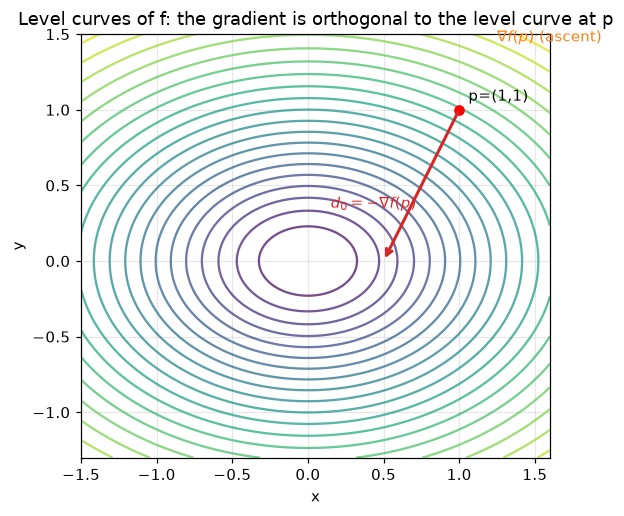

In [10]:
# numerical versions used from now on
f1 = lambda v: np.log(1 + v[0]**2 + 2*v[1]**2)
g1 = lambda v: np.array([2*v[0], 4*v[1]]) / (1 + v[0]**2 + 2*v[1]**2)
p1 = np.array([1.0, 1.0])
d0 = -g1(p1)
print("grad f(p) =", g1(p1), "  d0 =", d0, "  f(p) =", f1(p1))

fig, ax = plt.subplots(figsize=(6, 5))
contour(ax, f1, (-1.5, 1.6), (-1.3, 1.5))
ax.plot(*p1, "ro"); ax.annotate("p=(1,1)", p1, textcoords="offset points", xytext=(6, 6))
ax.annotate("", xy=p1 + g1(p1), xytext=p1, arrowprops=dict(arrowstyle="->", color="tab:orange", lw=2))
ax.annotate("", xy=p1 + d0, xytext=p1, arrowprops=dict(arrowstyle="->", color="tab:red", lw=2))
ax.text(1.25, 1.45, r"$\nabla f(p)$ (ascent)", color="tab:orange")
ax.text(0.15, 0.35, r"$d_0=-\nabla f(p)$", color="tab:red")
ax.set_title("Level curves of f: the gradient is orthogonal to the level curve at p")
plt.show()

**Reading the figure.** The level curves are ellipses elongated along $x$ (the coefficient of $y^2$ is larger, so $f$ varies faster in $y$). The gradient at $p$ is orthogonal to the level curve through $p$, and $d_0$ points to lower levels. Because the ellipses are elongated, $d_0$ does **not** point at the minimizer $(0,0)$.

## 1.2 Fixed step $\alpha=1$ (Question 2)

Update: $x_{k+1}=x_k-\alpha\,\nabla f(x_k)$. It is **not linear** in $x_k$ because of the factor $1/(1+q)$.

In [11]:
alpha = 1.0
x0 = p1.copy()
g0 = g1(x0);  x_1 = x0 - alpha * g0
g_1 = g1(x_1); x_2 = x_1 - alpha * g_1
print(f"x0 = {x0},   f(x0) = {f1(x0):.4f}")
print(f"x1 = x0 - {alpha}*{g0} = {x_1},   f(x1) = {f1(x_1):.4f}")
print(f"x2 = x1 - {alpha}*{g_1} = {x_2},   f(x2) = {f1(x_2):.4f}")
fixed1_path = [x0, x_1, x_2]

x0 = [1. 1.],   f(x0) = 1.3863
x1 = x0 - 1.0*[0.5 1. ] = [0.5 0. ],   f(x1) = 0.2231
x2 = x1 - 1.0*[0.8 0. ] = [-0.3  0. ],   f(x2) = 0.0862


## 1.3 Fixed step $\alpha=2$ (Question 3)

x0 = [1. 1.],   f = 1.3863
x1 = [ 0. -1.],   f = 1.0986
x2 = [0.     1.6667],   f = 1.8803


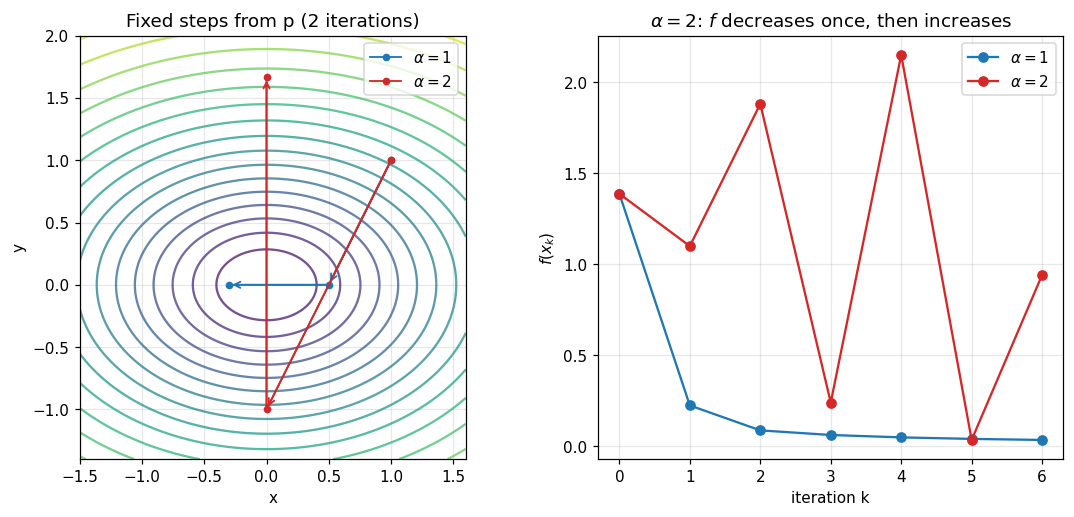

In [5]:
def fixed_path(alpha, n, x0=p1):
    pts = [np.array(x0, float)]
    for _ in range(n):
        pts.append(pts[-1] - alpha * g1(pts[-1]))
    return np.array(pts)

P2 = fixed_path(2.0, 2)
for k, pt in enumerate(P2):
    print(f"x{k} = {pt},   f = {f1(pt):.4f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
contour(axs[0], f1, (-1.5, 1.6), (-1.4, 2.0))
draw_path(axs[0], fixed_path(1.0, 2), "tab:blue", r"$\alpha=1$")
draw_path(axs[0], P2, "tab:red", r"$\alpha=2$")
axs[0].legend(); axs[0].set_title("Fixed steps from p (2 iterations)")

for al, c in [(1.0, "tab:blue"), (2.0, "tab:red")]:
    P = fixed_path(al, 6)
    axs[1].plot([f1(q) for q in P], "o-", color=c, label=rf"$\alpha={al:g}$")
axs[1].set_xlabel("iteration k"); axs[1].set_ylabel(r"$f(x_k)$"); axs[1].legend()
axs[1].set_title(r"$\alpha=2$: $f$ decreases once, then increases")
plt.show()

**Observation.** With $\alpha=2$ the first step lands on $(0,-1)$ and $f$ drops to $\ln 3$, but the second step jumps over the valley and $f$ rises to $\ln(59/9)\approx1.88>f(x_0)$. The direction is a descent direction at each point, but the step is too long.

## 1.4 Exact line search from $p$ (Question 4)

Along the line $x(\alpha)=p+\alpha d_0$ we define $\phi(\alpha)=f(p+\alpha d_0)$. SymPy gives the exact expression, $\phi'(0)$ and $\alpha^*$.

In [14]:
pt = sp.Matrix([1, 1]) + a * d0_sym
q_line = sp.expand(pt[0]**2 + 2*pt[1]**2)
phi_sym = sp.log(1 + q_line)
dphi_sym = sp.simplify(sp.diff(phi_sym, a))

display(Math(r"q(\alpha)=" + sp.latex(q_line)))
display(Math(r"\phi(\alpha)=\ln\left(" + sp.latex(sp.expand(1 + q_line)) + r"\right)"))
display(Math(r"\phi'(\alpha)=" + sp.latex(dphi_sym)))
display(Math(r"\phi'(0)=" + sp.latex(dphi_sym.subs(a, 0)) + r",\qquad -\|\nabla f(p)\|^2=" + sp.latex(-(g_p.T*g_p)[0])))

alpha_star_sym = sp.solve(sp.numer(sp.together(dphi_sym)), a)[0]
display(Math(r"\alpha_0^*=" + sp.latex(alpha_star_sym) + r"\approx" + f"{float(alpha_star_sym):.4f}"))
x1_exact = sp.Matrix([1, 1]) + alpha_star_sym * d0_sym
display(Math(r"x_1=" + sp.latex(x1_exact) + r",\qquad f(x_1)=\ln\frac{11}{9}=" + f"{float(f_sym.subs({x: x1_exact[0], y: x1_exact[1]})):.4f}"))
print("discriminant of 1+q(alpha):", sp.discriminant(sp.expand(1 + q_line), a), "< 0  =>  denominator never vanishes")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

discriminant of 1+q(alpha): -11 < 0  =>  denominator never vanishes


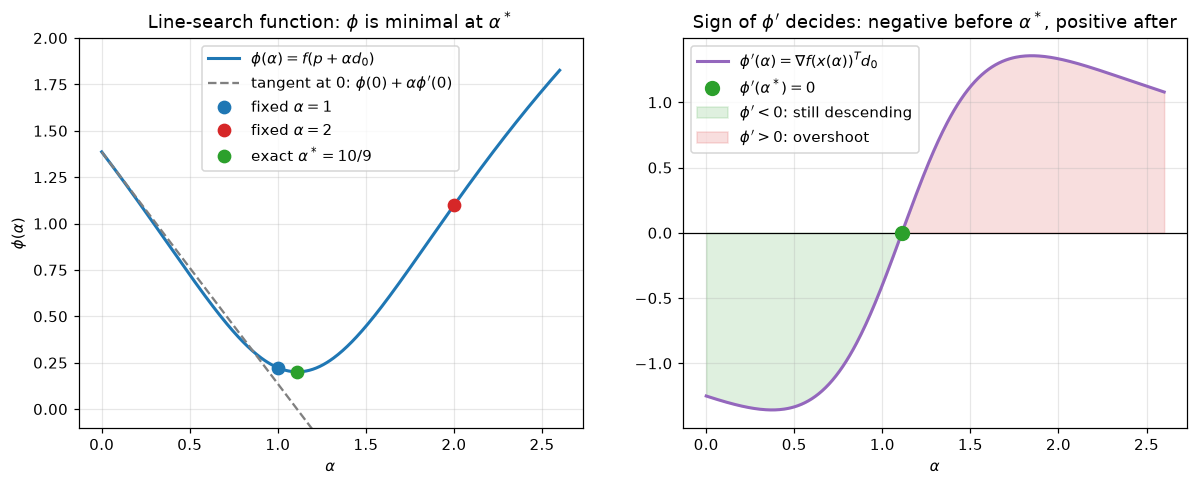

In [15]:
phi1, dphi1 = make_phi(f1, g1, p1, d0)
a_star = float(alpha_star_sym)
al = np.linspace(0, 2.6, 400)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axs[0]
ax.plot(al, phi1(al), lw=2, label=r"$\phi(\alpha)=f(p+\alpha d_0)$")
ax.plot(al, phi1(0) + dphi1(0) * al, "--", color="gray", label=r"tangent at 0: $\phi(0)+\alpha\phi'(0)$")
for v, c, n in [(1.0, "tab:blue", r"fixed $\alpha=1$"), (2.0, "tab:red", r"fixed $\alpha=2$"), (a_star, "tab:green", r"exact $\alpha^*=10/9$")]:
    ax.plot(v, phi1(v), "o", color=c, ms=8, label=n)
ax.set_xlabel(r"$\alpha$"); ax.set_ylabel(r"$\phi(\alpha)$"); ax.set_ylim(-0.1, 2.0); ax.legend()
ax.set_title(r"Line-search function: $\phi$ is minimal at $\alpha^*$")

ax = axs[1]
ax.plot(al, dphi1(al), lw=2, color="tab:purple", label=r"$\phi'(\alpha)=\nabla f(x(\alpha))^T d_0$")
ax.axhline(0, color="k", lw=0.8)
ax.plot(a_star, 0, "o", color="tab:green", ms=9, label=r"$\phi'(\alpha^*)=0$")
ax.fill_between(al, dphi1(al), 0, where=dphi1(al) < 0, color="tab:green", alpha=0.15, label=r"$\phi'<0$: still descending")
ax.fill_between(al, dphi1(al), 0, where=dphi1(al) > 0, color="tab:red", alpha=0.15, label=r"$\phi'>0$: overshoot")
ax.set_xlabel(r"$\alpha$"); ax.legend(); ax.set_title(r"Sign of $\phi'$ decides: negative before $\alpha^*$, positive after")
plt.show()

**Reading the figures.** The left plot shows why the step size matters: the three marked steps lie on the *same* line but give different values of $f$. The tangent at $\alpha=0$ has slope $\phi'(0)=-\|\nabla f(p)\|^2=-1.25$. The right plot shows $\phi'$: exact line search stops exactly where it changes sign.

## 1.5 Orthogonality $\nabla f(x_1)^Td_0=0$ (Question 5)

x1 = [ 0.4444 -0.1111]   (= (4/9, -1/9) = [ 0.4444 -0.1111] )
grad f(x1) = [ 0.7273 -0.3636]   (= (8/11, -4/11) = [ 0.7273 -0.3636] )
grad f(x1) . d0 = 1.6653345369377348e-16


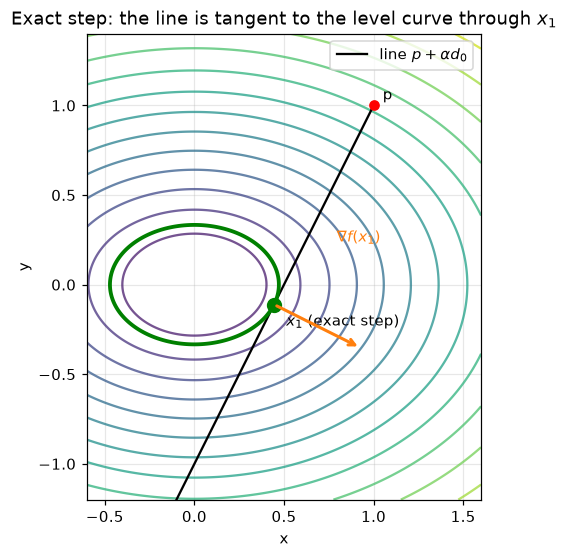

In [16]:
x1 = p1 + a_star * d0
g_x1 = g1(x1)
print("x1 =", x1, "  (= (4/9, -1/9) =", np.array([4/9, -1/9]), ")")
print("grad f(x1) =", g_x1, "  (= (8/11, -4/11) =", np.array([8/11, -4/11]), ")")
print("grad f(x1) . d0 =", g_x1 @ d0)

fig, ax = plt.subplots(figsize=(7, 5.5))
contour(ax, f1, (-0.6, 1.6), (-1.2, 1.4), levels=18)
seg = np.array([p1 + t * d0 for t in np.linspace(0, 2.4, 50)])
ax.plot(seg[:, 0], seg[:, 1], "k-", lw=1.5, label=r"line $p+\alpha d_0$")
ax.plot(*p1, "ro"); ax.annotate("p", p1, textcoords="offset points", xytext=(6, 4))
ax.plot(*x1, "go", ms=9); ax.annotate(r"$x_1$ (exact step)", x1, textcoords="offset points", xytext=(8, -14))
ax.annotate("", xy=x1 + 0.9 * g_x1 / np.linalg.norm(g_x1) * 0.6, xytext=x1, arrowprops=dict(arrowstyle="->", color="tab:orange", lw=2))
ax.text(x1[0] + 0.35, x1[1] + 0.35, r"$\nabla f(x_1)$", color="tab:orange")
# level curve through x1
X, Y = np.meshgrid(np.linspace(-0.6, 1.6, 400), np.linspace(-1.2, 1.4, 400))
ax.contour(X, Y, f1(np.array([X, Y])), levels=[f1(x1)], colors="green", linewidths=2.5)
ax.set_title("Exact step: the line is tangent to the level curve through $x_1$")
ax.legend(loc="upper right"); plt.show()

**Reading the figure.** The green curve is the level set $\{f=f(x_1)\}$. The line touches it at $x_1$ (tangency). Before $x_1$ the line crosses lower level sets, after $x_1$ it climbs again. Tangency is the geometric meaning of $\phi'(\alpha^*)=0$, and it means $\nabla f(x_1)\perp d_0$, so the next steepest-descent direction $d_1=-\nabla f(x_1)$ is orthogonal to $d_0$. This is the source of the zig-zag.

## 1.6 Second exact line search from $x_1$ (Question 6)

We now automate the exact step with a small helper: bracket the root of $\phi'$ (which starts negative) and call a root finder. The same helper will be reused in Part 3.

In [9]:
def exact_step(f, grad, x, d, a_max=1e3):
    """Exact line search: first root of phi'(a)=grad f(x+a d).d, bracketed by doubling, then Brent's method."""
    _, dphi = make_phi(f, grad, x, d)
    hi = 1e-3
    while dphi(hi) < 0 and hi < a_max:
        hi *= 2
    return brentq(dphi, 0.0, hi, xtol=1e-14)

rows = []
x = p1.copy()
for k in range(3):
    d = -g1(x)
    ak = exact_step(f1, g1, x, d)
    xn = x + ak * d
    rows.append(dict(k=k, x=x.round(4), alpha_star=ak, f_before=f1(x), f_after=f1(xn),
                     orth=g1(xn) @ d))
    x = xn
display(pd.DataFrame(rows))
print("Exact fractions: alpha_0* = 10/9 =", 10/9, ", alpha_1* = 55/108 =", 55/108)
print("x2 = (2/27, 2/27) =", np.array([2/27, 2/27]), ", f(x2) = ln(247/243) =", np.log(247/243))

,k,x,alpha_star,f_before,f_after,orth
0,0,"[1.0, 1.0]",1.1111,1.3863,0.2007,-3.0531e-15
1,1,"[0.4444, -0.1111]",0.5093,0.2007,0.0163,-1.0092e-15
2,2,"[0.0741, 0.0741]",0.2824,0.0163,0.0012,-6.4733e-19


Exact fractions: alpha_0* = 10/9 = 1.1111111111111112 , alpha_1* = 55/108 = 0.5092592592592593
x2 = (2/27, 2/27) = [0.0741 0.0741] , f(x2) = ln(247/243) = 0.016326893287428666


The column `orth` is $\nabla f(x_{k+1})^Td_k$: it is zero (up to rounding) at every iteration, as predicted. The steps $10/9$ and $55/108$ differ, which a fixed step cannot reproduce.

## 1.7 Fixed step versus exact line search (Question 7)

,fixed alpha=1,fixed alpha=2,exact line search
f(x0),1.3863,1.3863,1.3863
f(x1),0.2231,1.0986,0.2007
f(x2),0.0862,1.8803,0.0163


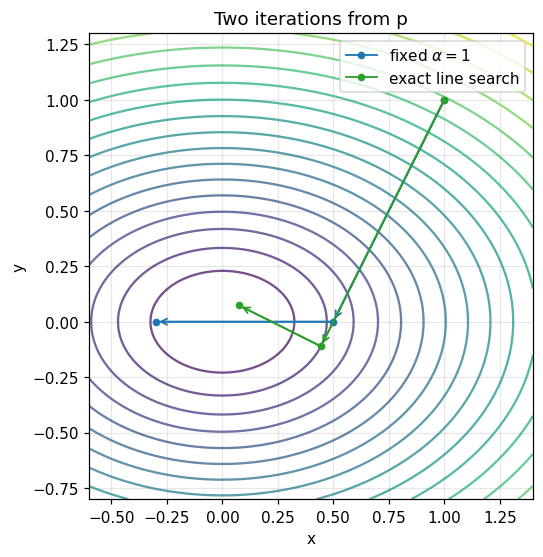

In [10]:
fixed1 = fixed_path(1.0, 2)
exact_pts = [p1]
x = p1.copy()
for k in range(2):
    d = -g1(x); x = x + exact_step(f1, g1, x, d) * d; exact_pts.append(x)
exact_pts = np.array(exact_pts)

table = pd.DataFrame({
    "fixed alpha=1": [f1(q) for q in fixed1],
    "fixed alpha=2": [f1(q) for q in fixed_path(2.0, 2)],
    "exact line search": [f1(q) for q in exact_pts],
}, index=["f(x0)", "f(x1)", "f(x2)"])
display(table)

fig, ax = plt.subplots(figsize=(7, 5.5))
contour(ax, f1, (-0.6, 1.4), (-0.8, 1.3), levels=22)
draw_path(ax, fixed1, "tab:blue", r"fixed $\alpha=1$")
draw_path(ax, exact_pts, "tab:green", "exact line search")
ax.legend(); ax.set_title("Two iterations from p"); plt.show()

## 1.8 Why there is no single condition on $\alpha$ here (Question 8)

For the pure quadratic $x^2+2y^2$ the update is $(x,y)\mapsto((1-2\alpha)x,(1-4\alpha)y)$, so convergence needs $\alpha<1/2$. Here the effective step is $\alpha/(1+q)$, which changes along the path, but near $(0,0)$ we have $q\approx0$ and the same local condition $\alpha<1/2$ appears. We test it by plotting the distance to the origin for several fixed steps.

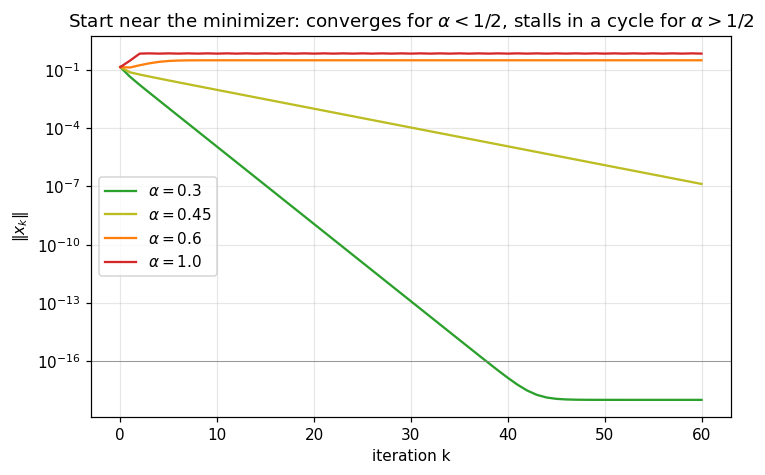

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for al_, c in [(0.3, "tab:green"), (0.45, "tab:olive"), (0.6, "tab:orange"), (1.0, "tab:red")]:
    P = fixed_path(al_, 60, x0=[0.1, 0.1])
    ax.semilogy(np.linalg.norm(P, axis=1) + 1e-18, color=c, label=rf"$\alpha={al_}$")
ax.axhline(1e-16, color="gray", lw=0.5)
ax.set_xlabel("iteration k"); ax.set_ylabel(r"$\|x_k\|$"); ax.legend()
ax.set_title(r"Start near the minimizer: converges for $\alpha<1/2$, stalls in a cycle for $\alpha>1/2$")
plt.show()

**Reading the figure.** For $\alpha=0.3$ and $0.45$ the distance goes to zero. For $\alpha=0.6$ and $1.0$ it does **not**: the iterates leave the neighborhood of the minimizer and settle on a cycle. The step $\alpha=1$ of Question 2 looked good only because $y_1=0$ exactly there; any perturbation of $y$ is multiplied by $1-4\alpha=-3$ near the origin and grows.

---
# Part 2. Exercise 2: Armijo backtracking when exact line search is not available

$$f(x,y)=x^4+y^2,\qquad p=(1,1),\qquad d=-\nabla f(p).$$

**Aim.** Armijo accepts a step when the real decrease is at least a fraction $c_1$ of the decrease predicted by the tangent line:
$$\phi(\alpha)\le\phi(0)+c_1\,\alpha\,\phi'(0).$$

## 2.1 Direction and $\phi$ (Question 1)

In [12]:
x, y, a = sp.symbols("x y alpha", real=True)
f2_sym = x**4 + y**2
g2_sym = sp.Matrix([sp.diff(f2_sym, v) for v in (x, y)])
g2_p = g2_sym.subs({x: 1, y: 1}); d_sym = -g2_p
pt = sp.Matrix([1, 1]) + a * d_sym
phi2_sym = sp.expand(f2_sym.subs({x: pt[0], y: pt[1]}))
dphi2_sym = sp.diff(phi2_sym, a)

display(Math(r"\nabla f(p)=" + sp.latex(g2_p) + r",\quad d=" + sp.latex(d_sym)))
display(Math(r"\phi(\alpha)=(1-4\alpha)^4+(1-2\alpha)^2=" + sp.latex(phi2_sym)))
display(Math(r"\phi'(\alpha)=" + sp.latex(dphi2_sym) + r",\quad \phi(0)=" + sp.latex(phi2_sym.subs(a, 0)) + r",\quad \phi'(0)=" + sp.latex(dphi2_sym.subs(a, 0))))
print("-||grad f(p)||^2 =", -(g2_p.T * g2_p)[0])

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

-||grad f(p)||^2 = -20


d = [-4. -2.]  phi(0) = 2.0  phi'(0) = -20.0


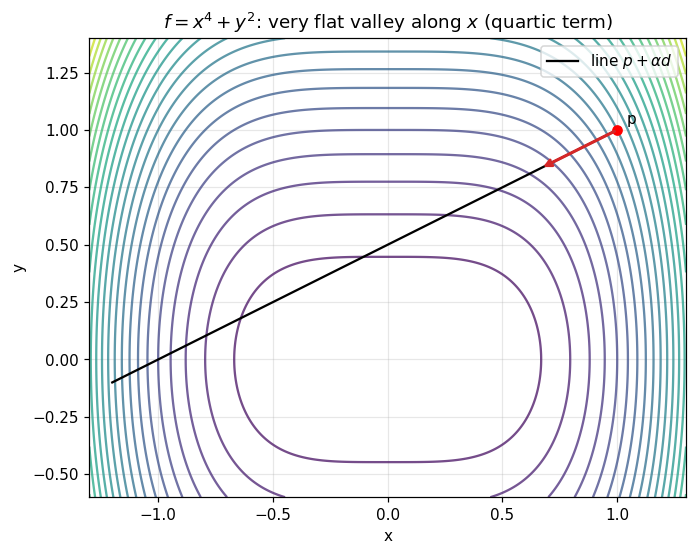

In [13]:
f2 = lambda v: v[0]**4 + v[1]**2
g2 = lambda v: np.array([4 * v[0]**3, 2 * v[1]])
p2 = np.array([1.0, 1.0])
d2 = -g2(p2)
phi2, dphi2 = make_phi(f2, g2, p2, d2)
phi0, dphi0 = phi2(0.0), dphi2(0.0)
print("d =", d2, " phi(0) =", phi0, " phi'(0) =", dphi0)

fig, ax = plt.subplots(figsize=(7, 5.5))
contour(ax, f2, (-1.3, 1.3), (-0.6, 1.4), levels=25)
line = np.array([p2 + t * d2 for t in np.linspace(0, 0.55, 40)])
ax.plot(line[:, 0], line[:, 1], "k-", lw=1.5, label=r"line $p+\alpha d$")
ax.plot(*p2, "ro"); ax.annotate("p", p2, textcoords="offset points", xytext=(6, 4))
ax.annotate("", xy=p2 + 0.25 * d2 / np.linalg.norm(d2) * 1.5, xytext=p2, arrowprops=dict(arrowstyle="->", color="tab:red", lw=2))
ax.set_title(r"$f=x^4+y^2$: very flat valley along $x$ (quartic term)"); ax.legend(); plt.show()

## 2.2 The exact step cannot be found by hand (Question 2)

$\phi'(\alpha)=0$ reads $4(1-4\alpha)^3+(1-2\alpha)=0$, a cubic. We locate the root with a sign table, then by bisection written as a loop.

In [14]:
display(Math(r"\phi'(\alpha)=0\iff " + sp.latex(sp.expand(dphi2_sym / 4)) + "=0"))
print("Roots of phi' (SymPy numeric):", [complex(r) for r in sp.Poly(dphi2_sym, a).nroots()])
print("Only one real root (phi'' = 192(1-4a)^2 + 8 > 0, phi convex).")

grid_vals = [0.35, 0.354, 0.355, 0.36]
display(pd.DataFrame({"alpha": grid_vals, "phi'(alpha)": [dphi2(v) for v in grid_vals]}))

<IPython.core.display.Math object>

Roots of phi' (SymPy numeric): [(0.3543902935601708+0j), (0.1978048532199146-0.12643377729935928j), (0.1978048532199146+0.12643377729935928j)]
Only one real root (phi'' = 192(1-4a)^2 + 8 > 0, phi convex).


,alpha,phi'(alpha)
0,0.350,-0.1760
1,0.354,-0.0161
2,0.355,0.0254
3,0.360,0.2429


,iter,lo,hi,mid,dphi_mid
9,10,0.3535,0.3555,0.3545,0.0042
10,11,0.3535,0.3545,0.3540,-0.0160
11,12,0.3540,0.3545,0.3542,-0.0059
12,13,0.3542,0.3545,0.3544,-0.0008
13,14,0.3544,0.3545,0.3544,0.0017
14,15,0.3544,0.3544,0.3544,0.0004


alpha* ~ 0.3544,   phi(alpha*) ~ 0.1152,   best decrease along the line = 1.8848


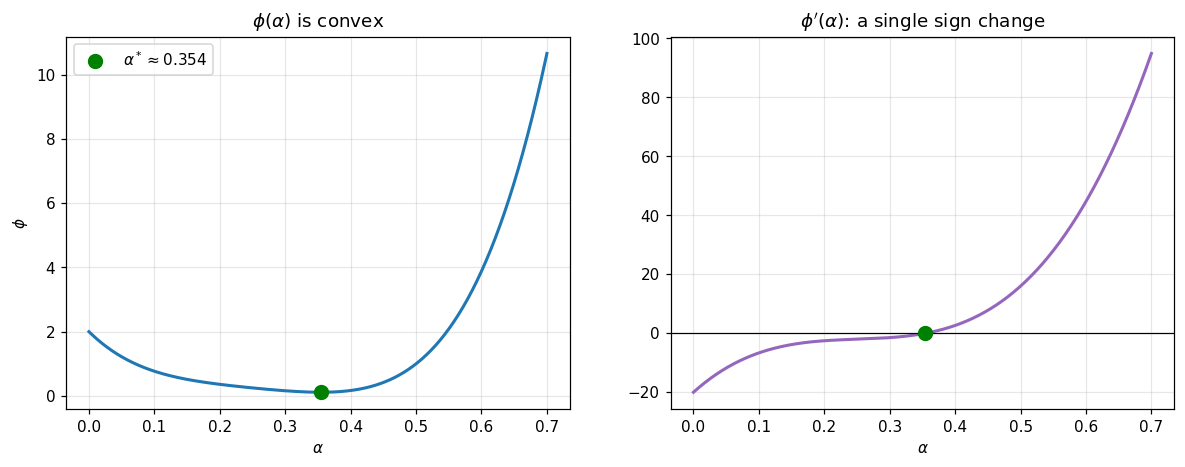

In [15]:
# Bisection loop on phi'
lo, hi = 0.0, 1.0
log = []
for it in range(1, 16):
    mid = 0.5 * (lo + hi)
    log.append(dict(iter=it, lo=lo, hi=hi, mid=mid, dphi_mid=dphi2(mid)))
    if dphi2(mid) < 0: lo = mid
    else: hi = mid
display(pd.DataFrame(log).tail(6))
a_star2 = 0.5 * (lo + hi)
print(f"alpha* ~ {a_star2:.4f},   phi(alpha*) ~ {phi2(a_star2):.4f},   best decrease along the line = {phi0 - phi2(a_star2):.4f}")

al = np.linspace(0, 0.7, 400)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
axs[0].plot(al, phi2(al), lw=2); axs[0].plot(a_star2, phi2(a_star2), "go", ms=9, label=r"$\alpha^*\approx0.354$")
axs[0].set_xlabel(r"$\alpha$"); axs[0].set_ylabel(r"$\phi$"); axs[0].legend(); axs[0].set_title(r"$\phi(\alpha)$ is convex")
axs[1].plot(al, dphi2(al), lw=2, color="tab:purple"); axs[1].axhline(0, color="k", lw=0.8)
axs[1].plot(a_star2, 0, "go", ms=9); axs[1].set_xlabel(r"$\alpha$"); axs[1].set_title(r"$\phi'(\alpha)$: a single sign change")
plt.show()

## 2.3 Armijo backtracking with $c_1=0.2$, $\beta=0.5$, $\alpha_0=1$ (Question 3)

Threshold: $\phi(0)+c_1\alpha\phi'(0)=2-4\alpha$. We write the loop explicitly and keep a log of every trial.

In [16]:
def armijo_log(phi, phi0, dphi0, c1, beta=0.5, alpha0=1.0, max_trials=60):
    """Backtracking; returns accepted step and a log of every trial."""
    alpha, log = alpha0, []
    for t in range(1, max_trials + 1):
        val, thr = phi(alpha), phi0 + c1 * alpha * dphi0
        ok = val <= thr
        log.append(dict(trial=t, alpha=alpha, phi=val, threshold=thr, decision="ACCEPT" if ok else "reject"))
        if ok: break
        alpha *= beta
    return alpha, pd.DataFrame(log)

alpha_arm, log_arm = armijo_log(phi2, phi0, dphi0, c1=0.2)
display(log_arm)
x1_arm = p2 + alpha_arm * d2
print(f"accepted alpha = {alpha_arm},  x1 = {x1_arm},  f(x1) = {f2(x1_arm):.4f}")

,trial,alpha,phi,threshold,decision
0,1,1.00,82.00,-2.0,reject
1,2,0.50,1.00,0.0,reject
2,3,0.25,0.25,1.0,ACCEPT


accepted alpha = 0.25,  x1 = [0.  0.5],  f(x1) = 0.2500


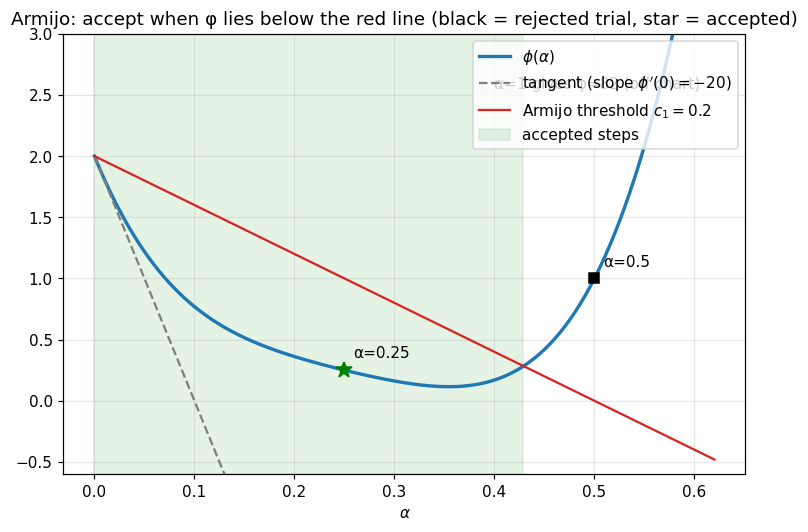

In [17]:
al = np.linspace(0, 0.62, 500)
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.plot(al, phi2(al), lw=2.2, label=r"$\phi(\alpha)$")
ax.plot(al, phi0 + dphi0 * al, "--", color="gray", label=r"tangent (slope $\phi'(0)=-20$)")
ax.plot(al, phi0 + 0.2 * dphi0 * al, color="tab:red", label=r"Armijo threshold $c_1=0.2$")
ok = phi2(al) <= phi0 + 0.2 * dphi0 * al
ax.fill_between(al, -0.6, 3, where=ok, color="tab:green", alpha=0.12, label="accepted steps")
for _, r in log_arm.iterrows():
    if r.phi < 3:
        ax.plot(r.alpha, r.phi, "ks" if r.decision == "reject" else "g*", ms=11 if r.decision == "ACCEPT" else 7)
        ax.annotate(f"α={r.alpha:g}", (r.alpha, r.phi), textcoords="offset points", xytext=(6, 8))
ax.text(0.40, 2.55, "α=1 gives φ=82 (off chart)", color="k")
ax.set_ylim(-0.6, 3); ax.set_xlabel(r"$\alpha$"); ax.legend(loc="upper right")
ax.set_title("Armijo: accept when φ lies below the red line (black = rejected trial, star = accepted)")
plt.show()

**Reading the figure.** The real function $\phi$ is convex, so it lies *above* its tangent (grey). The red line is the tangent tilted by the factor $c_1$. Armijo accepts every $\alpha$ for which $\phi$ is below the red line: the green zone $[0,0.429]$. Backtracking starts at $\alpha=1$ (far outside), halves until it first enters the green zone, and accepts $\alpha=0.25$. No equation was solved and no derivative was evaluated after $\phi'(0)$.

## 2.4 Comparison with exact line search (Question 4)

Armijo : alpha=0.250, f(x1)=0.2500, decrease=1.7500
Exact  : alpha=0.354, f(x1)=0.1152, decrease=1.8848
Armijo obtains 93% of the best possible decrease along the line


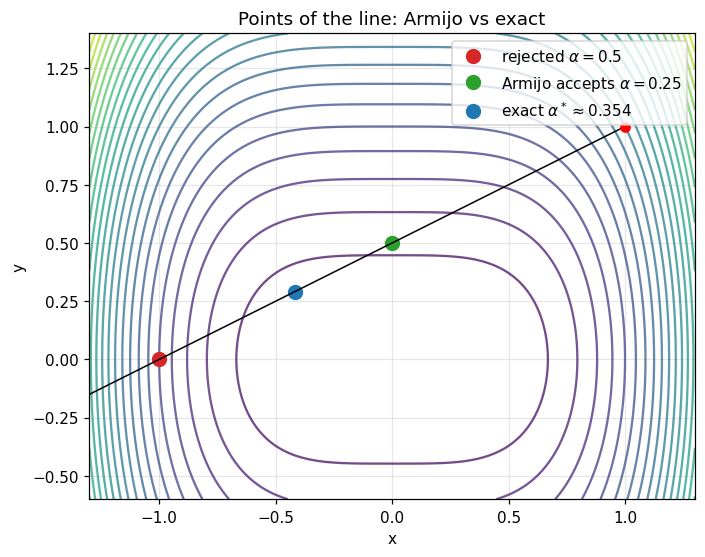

In [18]:
dec_arm   = phi0 - phi2(alpha_arm)
dec_exact = phi0 - phi2(a_star2)
print(f"Armijo : alpha={alpha_arm:.3f}, f(x1)={phi2(alpha_arm):.4f}, decrease={dec_arm:.4f}")
print(f"Exact  : alpha={a_star2:.3f}, f(x1)={phi2(a_star2):.4f}, decrease={dec_exact:.4f}")
print(f"Armijo obtains {100*dec_arm/dec_exact:.0f}% of the best possible decrease along the line")

fig, ax = plt.subplots(figsize=(7.2, 5.5))
contour(ax, f2, (-1.3, 1.3), (-0.6, 1.4), levels=25)
for t, c, n in [(0.5, "tab:red", r"rejected $\alpha=0.5$"), (0.25, "tab:green", r"Armijo accepts $\alpha=0.25$"), (a_star2, "tab:blue", r"exact $\alpha^*\approx0.354$")]:
    q = p2 + t * d2; ax.plot(*q, "o", color=c, ms=9, label=n)
ln = np.array([p2 + t * d2 for t in np.linspace(0, 0.58, 40)]); ax.plot(ln[:, 0], ln[:, 1], "k-", lw=1)
ax.plot(*p2, "ro"); ax.legend(loc="upper right"); ax.set_title("Points of the line: Armijo vs exact"); plt.show()

## 2.5 Effect of $c_1$ (Question 5)

We loop over three values of $c_1$ and compute the number of trials, the accepted step, the decrease and the accepted interval $[0,\alpha_{\max}]$.

,c1,trials,accepted alpha,f(x1),decrease,% of best,accepted set
0,0.01,2,0.5000,1.000,1.000,53.0563,"[0, 0.5429]"
1,0.20,3,0.2500,0.250,1.750,92.8485,"[0, 0.4291]"
2,0.90,7,0.0156,1.711,0.289,15.3358,"[0, 0.0211]"


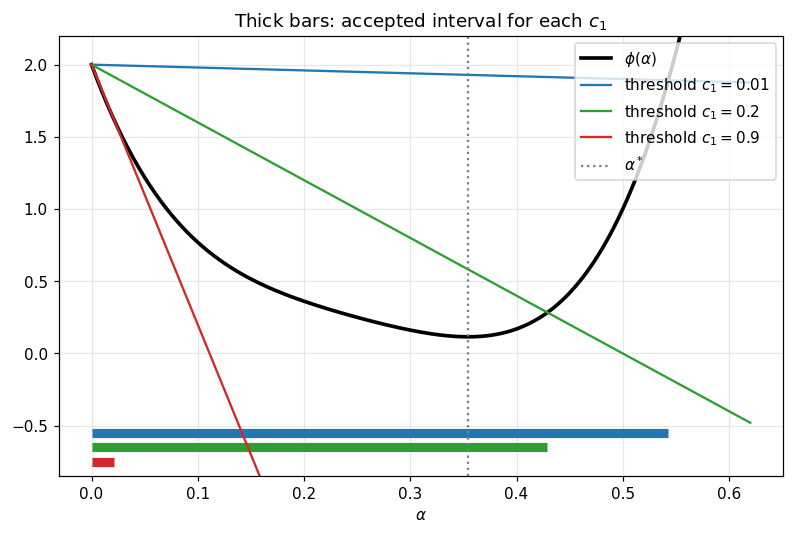

In [19]:
grid = np.linspace(0, 1, 200001)
phig = phi2(grid)

def accepted_max(c1):
    ok = phig <= phi0 + c1 * grid * dphi0
    return grid[np.argmax(~ok) - 1]            # first failure ends the accepted interval [0, amax]

rows = []
for c1 in [0.01, 0.2, 0.9]:
    al_acc, lg = armijo_log(phi2, phi0, dphi0, c1)
    dec = phi0 - phi2(al_acc)
    rows.append({"c1": c1, "trials": len(lg), "accepted alpha": al_acc, "f(x1)": phi2(al_acc),
                 "decrease": dec, "% of best": 100 * dec / dec_exact, "accepted set": f"[0, {accepted_max(c1):.4f}]"})
display(pd.DataFrame(rows))

al = np.linspace(0, 0.62, 500)
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.plot(al, phi2(al), lw=2.4, color="k", label=r"$\phi(\alpha)$")
for c1, c in [(0.01, "tab:blue"), (0.2, "tab:green"), (0.9, "tab:red")]:
    ax.plot(al, phi0 + c1 * dphi0 * al, color=c, label=rf"threshold $c_1={c1}$")
    am = accepted_max(c1)
    ax.plot([0, am], [-0.55 - 0.1 * [0.01, 0.2, 0.9].index(c1)] * 2, "-", color=c, lw=6, solid_capstyle="butt")
ax.axvline(a_star2, color="gray", ls=":", label=r"$\alpha^*$")
ax.set_ylim(-0.85, 2.2); ax.set_xlabel(r"$\alpha$"); ax.legend(loc="upper right")
ax.set_title("Thick bars: accepted interval for each $c_1$")
plt.show()

**Reading the figure.** The thick bars at the bottom are the accepted sets. A **small** $c_1$ (blue) accepts a long interval that reaches *beyond* $\alpha^*$, so Armijo can accept an overshooting step. A **large** $c_1$ (red) forces the red line almost down to the tangent, so only very short steps pass: backtracking needs many trials and ends with a tiny step that excludes $\alpha^*$. Armijo protects against bad steps but is not a search for the best step.

## 2.6 Bonus: largest $c_1$ that accepts the exact step (Question 6)

$\alpha^*$ is accepted iff $\phi(\alpha^*)\le\phi(0)+c_1\alpha^*\phi'(0)$, i.e. $c_1\le\dfrac{\phi(0)-\phi(\alpha^*)}{\alpha^*\,|\phi'(0)|}$. Geometrically, $c_1^{\max}$ is the slope ratio of the **chord** from $(0,\phi(0))$ to $(\alpha^*,\phi(\alpha^*))$ over the tangent.

c1_max = 0.2659
c1=0.2: alpha* accepted? True
c1=0.26: alpha* accepted? True
c1=0.27: alpha* accepted? False
c1=0.3: alpha* accepted? False


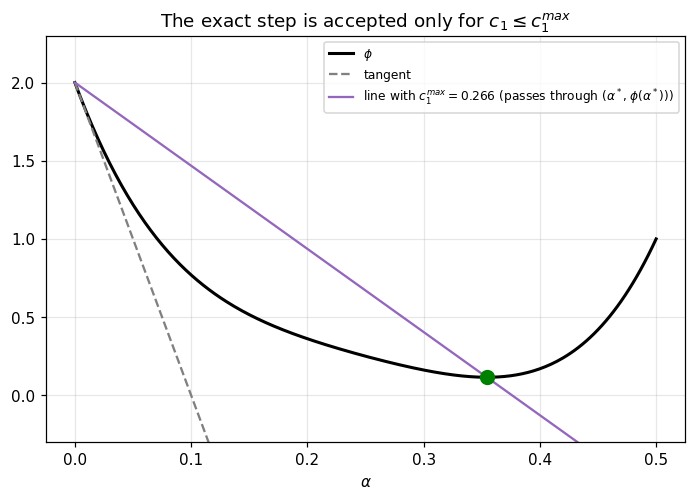

In [20]:
c1_max = (phi0 - phi2(a_star2)) / (a_star2 * abs(dphi0))
print(f"c1_max = {c1_max:.4f}")
for c1 in [0.2, 0.26, 0.27, 0.3]:
    print(f"c1={c1}: alpha* accepted? {phi2(a_star2) <= phi0 + c1 * a_star2 * dphi0}")

al = np.linspace(0, 0.5, 300)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(al, phi2(al), "k", lw=2, label=r"$\phi$")
ax.plot(al, phi0 + dphi0 * al, "--", color="gray", label="tangent")
ax.plot(al, phi0 + c1_max * dphi0 * al, color="tab:purple", label=rf"line with $c_1^{{max}}={c1_max:.3f}$ (passes through $(\alpha^*,\phi(\alpha^*))$)")
ax.plot(a_star2, phi2(a_star2), "go", ms=9)
ax.set_ylim(-0.3, 2.3); ax.set_xlabel(r"$\alpha$"); ax.legend(fontsize=8); ax.set_title(r"The exact step is accepted only for $c_1\leq c_1^{max}$")
plt.show()

---
# Part 3. Loops: gradient descent with fixed step, exact line search and Armijo

Now the whole algorithm is automated:
$$x_{k+1}=x_k+\alpha_k d_k,\qquad d_k=-\nabla f(x_k),$$
and only the **rule** that chooses $\alpha_k$ changes: a constant, the exact minimizer of $\phi$, or Armijo backtracking.

In [21]:
def rule_fixed(alpha):
    def rule(f, grad, x, d):
        return alpha, 0
    rule.__name__ = f"fixed alpha={alpha:g}"; return rule

def rule_exact():
    def rule(f, grad, x, d):
        _, dphi = make_phi(f, grad, x, d)
        n = [0]
        def counted(t): n[0] += 1; return dphi(t)
        hi = 1e-3
        while counted(hi) < 0 and hi < 1e3: hi *= 2
        return brentq(counted, 0.0, hi, xtol=1e-14), n[0]
    rule.__name__ = "exact line search"; return rule

def rule_armijo(c1=0.1, beta=0.5, alpha0=1.0):
    def rule(f, grad, x, d):
        phi, dphi = make_phi(f, grad, x, d)
        p0, s0 = phi(0.0), dphi(0.0)
        al, n = alpha0, 0
        while True:
            n += 1
            if phi(al) <= p0 + c1 * al * s0 or al < 1e-16: return al, n
            al *= beta
    rule.__name__ = f"Armijo c1={c1:g}"; return rule

def gradient_descent(f, grad, x0, rule, n_iter=30, tol=1e-8):
    """Generic loop. Records iterates, f values, steps and the number of phi-evaluations used by the rule."""
    x = np.array(x0, float)
    hist = dict(x=[x.copy()], f=[f(x)], alpha=[], evals=[])
    for k in range(n_iter):
        g = grad(x)
        if np.linalg.norm(g) < tol: break
        d = -g
        alpha, ne = rule(f, grad, x, d)
        x = x + alpha * d
        if not np.all(np.isfinite(x)) or np.linalg.norm(x) > 1e8:
            break
        hist["x"].append(x.copy()); hist["f"].append(f(x)); hist["alpha"].append(alpha); hist["evals"].append(ne)
    hist["x"] = np.array(hist["x"]); return hist

def compare(f, grad, x0, rules, n_iter, xlim, ylim, title, n_path=8):
    results = {r.__name__: gradient_descent(f, grad, x0, r, n_iter) for r in rules}
    colors = plt.cm.tab10(np.arange(len(rules)))
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
    contour(axs[0], f, xlim, ylim, levels=22)
    for (name, h), c in zip(results.items(), colors):
        draw_path(axs[0], h["x"][: n_path + 1], c, name)
    axs[0].legend(fontsize=7); axs[0].set_title(f"First {n_path} iterates")
    for (name, h), c in zip(results.items(), colors):
        axs[1].semilogy(np.array(h["f"]) + 1e-18, "o-", ms=3, color=c, label=name)
        axs[2].plot(h["alpha"], "o-", ms=3, color=c, label=name)
    axs[1].set_xlabel("iteration k"); axs[1].set_ylabel(r"$f(x_k)$"); axs[1].set_title("Objective value (log scale)")
    axs[2].set_xlabel("iteration k"); axs[2].set_ylabel(r"step $\alpha_k$"); axs[2].set_title("Step sizes used")
    axs[2].set_yscale("log"); axs[1].legend(fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.show()
    rows = [{"method": n, "iterations": len(h["alpha"]), "final f": h["f"][-1], "||x_final||": np.linalg.norm(h["x"][-1]),
             "phi-evals / iter": np.mean(h["evals"]) if h["evals"] else np.nan} for n, h in results.items()]
    return results, pd.DataFrame(rows)

## 3.1 Exercise 1 function: $f=\ln(1+x^2+2y^2)$ from a generic start

We start from $x_0=(1.5,\,0.7)$ instead of $p=(1,1)$. From $p$, a step $\alpha=1$ sets $y_1=0$ exactly, which makes some methods look luckier than they are.

Methods: fixed $\alpha=0.3$ (safe), fixed $\alpha=1$ (looked good for two steps), exact line search, Armijo ($c_1=0.1$, $\beta=0.6$, $\alpha_0=1$). We use $\beta=0.6$ here because with $\beta=0.5$ the trial $\alpha=0.25$ is exactly the step that cancels the $y$-component near the origin, which would flatter Armijo by coincidence.

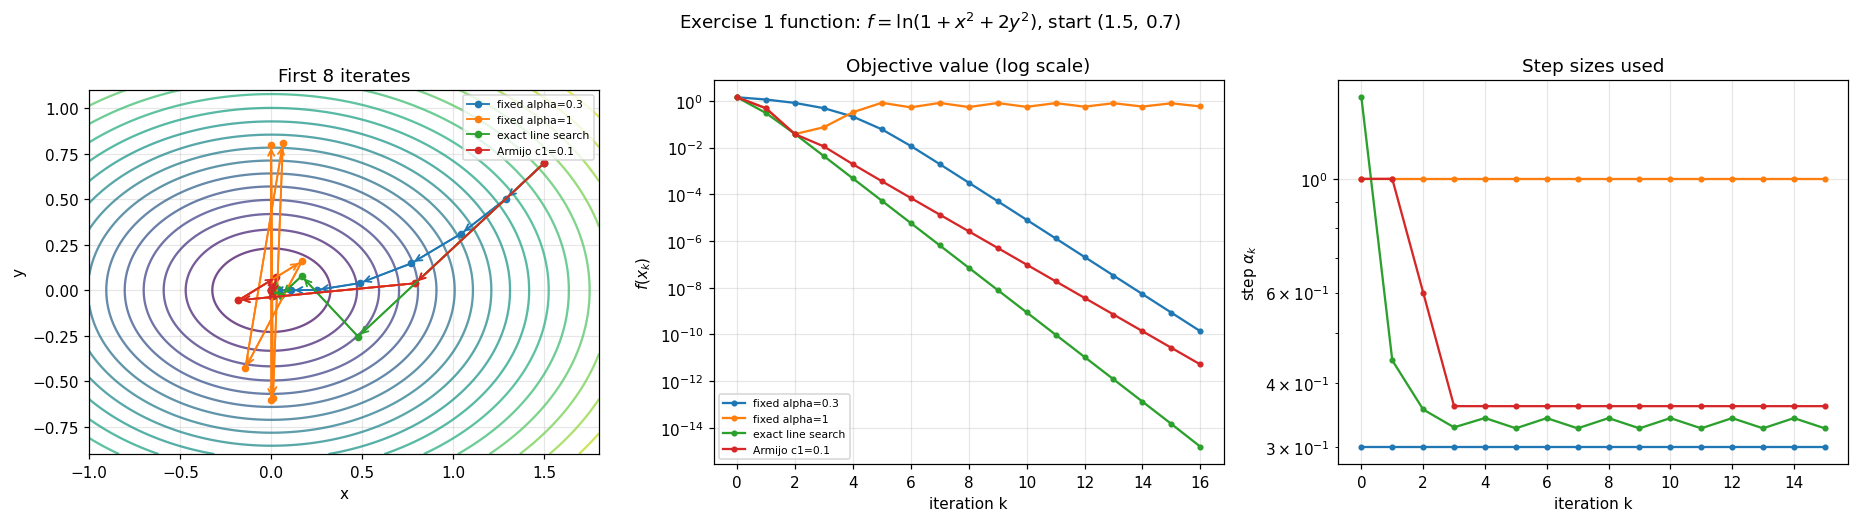

,method,iterations,final f,||x_final||,phi-evals / iter
0,fixed alpha=0.3,16,1.3696e-10,1.1703e-05,0.0000
1,fixed alpha=1,16,5.8180e-01,6.2819e-01,0.0000
2,exact line search,16,1.5543e-15,3.7174e-08,15.6875
3,Armijo c1=0.1,16,5.1759e-12,1.6087e-06,2.6875


In [22]:
rules1 = [rule_fixed(0.3), rule_fixed(1.0), rule_exact(), rule_armijo(0.1, 0.6, 1.0)]
start1 = np.array([1.5, 0.7])
res1, tab1 = compare(f1, g1, start1, rules1, n_iter=16, xlim=(-1.0, 1.8), ylim=(-0.9, 1.1),
                     title=r"Exercise 1 function: $f=\ln(1+x^2+2y^2)$, start $(1.5,\,0.7)$")
display(tab1)

**Reading the figures.**
- *Left:* exact line search (and Armijo) make long, adapted steps; the exact method shows the right-angle turns caused by orthogonal successive directions. Fixed $\alpha=1$ bounces across the valley.
- *Middle:* the exact method and Armijo reach very small $f$ quickly; fixed $\alpha=0.3$ converges steadily; fixed $\alpha=1$ stagnates, as predicted by the local analysis ($\alpha>1/2$).
- *Right:* the fixed steps are horizontal lines, whereas the exact and Armijo steps change at each iteration. This adaptivity is the whole point of line search.

## 3.2 Exercise 2 function: $f=x^4+y^2$ from a generic start

We start from $x_0=(1.2,\,0.8)$. From $p=(1,1)$, the step $\alpha=0.25$ sets $x_1=0$ exactly (since $d_x=-4$), which would hide the slow quartic behavior.

Here exact line search needs a cubic solve at *every* iteration, whereas Armijo needs only a few evaluations of $\phi$ (see the last column of the table: `phi-evals / iter`).

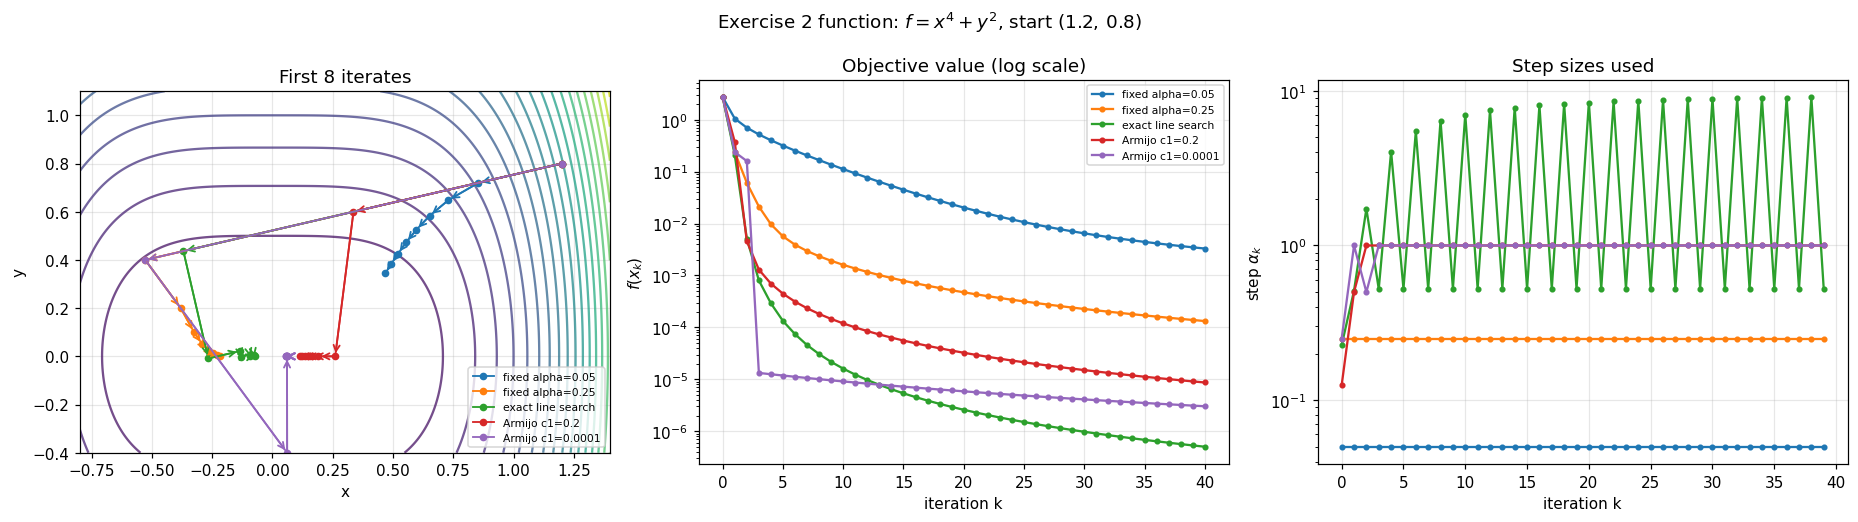

,method,iterations,final f,||x_final||,phi-evals / iter
0,fixed alpha=0.05,40,3.3031e-03,0.2375,0.000
1,fixed alpha=0.25,40,1.3242e-04,0.1073,0.000
2,exact line search,40,5.0213e-07,0.0266,18.675
3,Armijo c1=0.2,40,8.6705e-06,0.0543,1.100
4,Armijo c1=0.0001,40,3.0234e-06,0.0417,1.075


In [23]:
rules2 = [rule_fixed(0.05), rule_fixed(0.25), rule_exact(), rule_armijo(0.2, 0.5, 1.0), rule_armijo(1e-4, 0.5, 1.0)]
start2 = np.array([1.2, 0.8])
res2, tab2 = compare(f2, g2, start2, rules2, n_iter=40, xlim=(-0.8, 1.4), ylim=(-0.4, 1.1),
                     title=r"Exercise 2 function: $f=x^4+y^2$, start $(1.2,\,0.8)$")
display(tab2)

**Reading the figures.**
- The valley of $x^4+y^2$ becomes very flat near $x=0$ (the $x$-curvature vanishes), so *every* method slows down: once $y$ is small, $f$ decreases only polynomially in $k$, not geometrically (the curves bend instead of being straight lines on the log plot).
- Fixed steps cannot adapt: $\alpha=0.05$ is safe but slow, and $\alpha=0.25$ is the best fixed choice early on but becomes too small once the gradient shrinks.
- *Right plot:* exact line search takes **larger and larger steps** (up to about 9, oscillating) because the optimal step grows as the gradient shrinks along a flat valley. Armijo is capped by $\alpha_0=1$, so it is slower in the long run, but it needs about 1 evaluation of $\phi$ per iteration against about 19 for exact line search (last column of the table). Using a larger $\alpha_0$ (or a step-increase rule) would remove this cap.
- $c_1=0.2$ and $c_1=10^{-4}$ give similar steps here; the smaller value accepts the first trial more often.

## 3.3 Sensitivity to the fixed step: Armijo needs no tuning

We scan the fixed step $\alpha$ for both functions, run 40 iterations, and compare the final $f$ with Armijo (horizontal line).

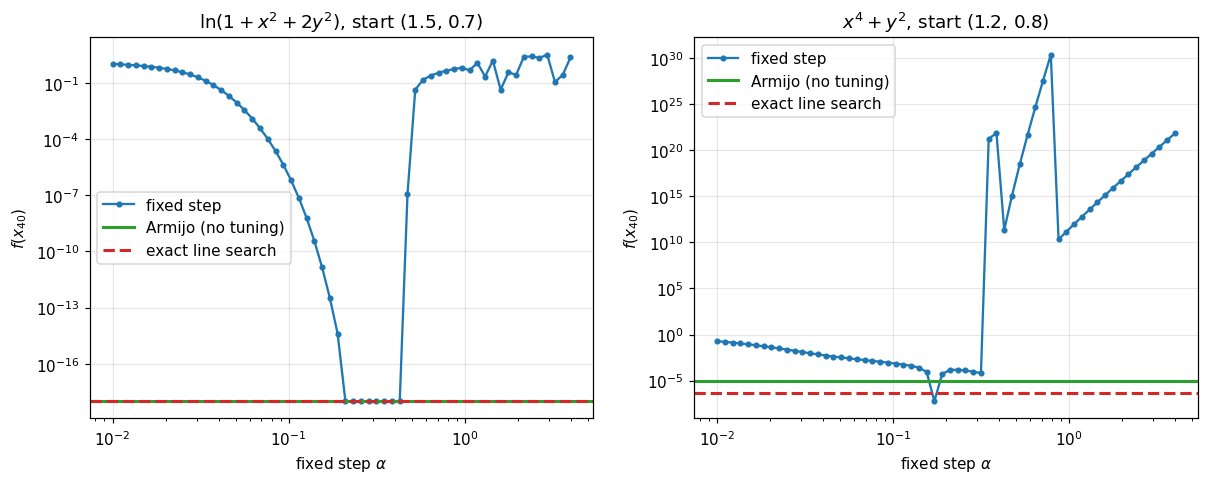

In [24]:
def final_f(f, grad, x0, rule, n=40):
    with np.errstate(all="ignore"):
        h = gradient_descent(f, grad, x0, rule, n)
    v = h["f"][-1]
    return v if np.isfinite(v) else 1e8

alphas = np.logspace(-2, 0.6, 60)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (f, g, x0, name) in zip(axs, [(f1, g1, start1, r"$\ln(1+x^2+2y^2)$, start (1.5, 0.7)"), (f2, g2, start2, r"$x^4+y^2$, start (1.2, 0.8)")]):
    vals = [final_f(f, g, x0, rule_fixed(al_)) for al_ in alphas]
    ax.loglog(alphas, np.maximum(vals, 1e-18), "o-", ms=3, label="fixed step")
    ax.axhline(max(final_f(f, g, x0, rule_armijo(0.1)), 1e-18), color="tab:green", lw=2, label="Armijo (no tuning)")
    ax.axhline(max(final_f(f, g, x0, rule_exact()), 1e-18), color="tab:red", ls="--", lw=2, label="exact line search")
    ax.set_xlabel(r"fixed step $\alpha$"); ax.set_ylabel(r"$f(x_{40})$"); ax.legend(); ax.set_title(name)
plt.show()

**Reading the figure.** A fixed step has a narrow good range: below it the method is slow, above it the method fails (the curve jumps up). Armijo reaches a comparable or better value without anyone choosing $\alpha$ in advance, which is why approximate line search is the standard choice when exact line search is too expensive.

---
# Part 4. Summary

| Idea | What the figures showed |
|---|---|
| Direction is not enough | Three steps on the same line gave three different values of $\phi$ (1.3). |
| Exact line search | $\phi'(\alpha^*)=0$, tangency to a level curve, orthogonal successive gradients (1.4, 1.5). |
| Fixed step | Works only in a limited range ($\alpha<1/2$ near the minimizer); outside it $f$ can increase or the iterates cycle (1.3, 1.8, 3.3). |
| When exact search fails | $\phi'=0$ became a cubic; the root was only found numerically (2.2). |
| Armijo | Accepts steps whose $\phi$ lies below the tilted tangent; $c_1$ small is permissive, $c_1$ large is restrictive (2.3, 2.5). |
| Armijo is not a minimizer | The exact step is rejected for $c_1>c_1^{max}\approx0.266$ (2.6). |
| Loops | Only the step rule changes in `gradient_descent`; Armijo gives adaptive steps at the cost of a few $\phi$ evaluations (Part 3). |

